# 01 — Hypothesis & Driver Analysis

Phạm vi chỉ bước 3: chẩn đoán mô tả, không recommendation/model/dashboard. Đọc analysis-ready bước 2; raw và bước 1/2 không thay đổi. Mean source ER có công thức chưa xác nhận và không phải rate tổng hợp. Tổng volume là tổng record, chưa xác nhận unique-post grain.


# Hypothesis Setup

Đối tượng chính: Entertainment so với non-Entertainment trong 16 cohort tháng trọn (01/2024–04/2025). Tháng 05/2025 partial chỉ dùng kiểm tra độ nhạy. Secondary: Product Promotion, kiểm tra riêng ở mức giới hạn.

| ID | Driver / giả thuyết | Logic | Metric | Cách kiểm tra |
| --- | --- | --- | --- | --- |
| H1 | Platform mix | Entertainment tập trung ở kênh có ER thấp | Source ER mean/median, record mix, Views | So cùng platform; chuẩn hóa mix và decomposition |
| H2 | Post Type | Cơ cấu định dạng liên quan đến một phần gap | ER, record mix, Views/Engagement | So cùng post type; chuẩn hóa mix; kiểm tra platform × post type |
| H3 | Organic/Sponsored | Cơ cấu phân phối khác nhau liên quan đến gap | ER, record mix | So cùng Content_Type; decomposition |
| H4 | Region | Entertainment tập trung ở region có ER thấp | ER, record mix | So cùng Region; decomposition, leave-one-region-out |
| H5 | Month/Day/Hour | Cơ cấu thời điểm đăng liên quan đến gap | ER, số record | So cùng Month/Weekday/Post_Hour; không quy đổi timezone |
| H6 | Main hashtag | Nhóm hashtag gắn với ER thấp | ER, số record và common support | Cross-tab category × hashtag; chỉ so tag có cả hai nhóm đủ mẫu |
| H7 | Interaction | Một tổ hợp platform/định dạng/phân phối tập trung phần lớn gap | ER, cell n, Views; gap chuẩn hóa | So cùng platform × post type, platform × Content_Type, region × post type; xác định coverage |
| H8 | Độ nhạy | Gap phụ thuộc mẫu nhỏ/outlier/mã lặp/cách đo | Mean/median, gap pp | Ngưỡng 10/30/50; winsor 1%; trọng số mã; loại lần lượt platform/region |

Không giả thuyết nào được coi là causal từ phép so sánh observational. “Driver” là yếu tố liên quan được kiểm tra; không mặc định mọi hypothesis phải được ủng hộ.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/Social_Media_Content_Performance_Dataset.xlsx").exists())
step2 = next(p for p in root.iterdir() if p.is_dir() and p.name.startswith("2."))
out = next(p for p in root.iterdir() if p.is_dir() and p.name.startswith("3."))
tables = out / "artifacts/tables"
figures = out / "artifacts/figures"
for path in [tables, figures]:
    path.mkdir(parents=True, exist_ok=True)
source = pd.read_csv(step2 / "artifacts/analysis_ready.csv",
                     parse_dates=["Post_Date", "Post_Published_At"])
assert source.Source_Row.is_unique
for col in ["Engagement_Rate", "Views", "Impressions", "Engagement"]:
    source.loc[source["Invalid_"+col], col] = np.nan
# No new cleaning, imputation, recoding or deduplication.
# Main analysis uses full publication-month cohorts; partial month is sensitivity only.
data = source.loc[~source.Partial_Month].copy()
data["Group"] = np.where(data.Content_Category.eq("Entertainment"), "Entertainment", "Rest")
N_E = int(data.Group.eq("Entertainment").sum())
N_R = len(data)-N_E
THRESHOLD = 30  # per group per cell; descriptive screening, not a power calculation

def save(table, name):
    table.to_csv(tables / (name+".csv"), index=True)

def pairs(frame, columns, threshold=THRESHOLD):
    groups = {label: g for label, g in frame.groupby(columns, dropna=False)}
    rows = []
    for label, group in groups.items():
        labels = label if isinstance(label, tuple) else (label,)
        row = dict(zip(columns, labels))
        for short, mask in [("E", group.Content_Category.eq("Entertainment")),
                            ("R", ~group.Content_Category.eq("Entertainment"))]:
            g = group.loc[mask]
            row.update({"n_"+short: len(g), "er_n_"+short: g.Engagement_Rate.count(),
                "mean_"+short: g.Engagement_Rate.mean()*100,
                "median_"+short: g.Engagement_Rate.median()*100 if len(g) else np.nan,
                "views_"+short: g.Views.sum(min_count=1),
                "impressions_"+short: g.Impressions.sum(min_count=1),
                "engagement_"+short: g.Engagement.sum(min_count=1)})
        row['gap_pp'] = row['mean_R']-row['mean_E']
        row['median_gap_pp'] = row['median_R']-row['median_E']
        row['eligible'] = min(row['er_n_E'], row['er_n_R']) >= threshold
        rows.append(row)
    result = pd.DataFrame(rows).set_index(columns)
    result['mix_E_pct'] = result.n_E / frame.Content_Category.eq('Entertainment').sum()*100
    result['mix_R_pct'] = result.n_R / (~frame.Content_Category.eq('Entertainment')).sum()*100
    return result

def decomposition(table, driver):
    # Common support with adequate sample in BOTH groups; excluded cells retained in tables.
    t = table.loc[table.eligible].copy()
    if t.empty:
        return {"driver": driver, "eligible_cells": 0}
    pE, pR = t.n_E/t.n_E.sum(), t.n_R/t.n_R.sum()
    mE, mR = t.mean_E, t.mean_R
    composition = ((pR-pE)*(mR+mE)/2).sum()
    within = ((pR+pE)/2*(mR-mE)).sum()
    subset_gap = (pR*mR).sum()-(pE*mE).sum()
    assert np.isclose(composition+within, subset_gap)
    return {"driver": driver, "eligible_cells": len(t),
        "coverage_E_pct": t.n_E.sum()/N_E*100, "coverage_R_pct": t.n_R.sum()/N_R*100,
        "supported_subset_gap_pp": subset_gap, "composition_pp": composition,
        "within_segment_pp": within,
        "rest_standardized_to_E_pct": (pE*mR).sum(), "E_supported_mean_pct": (pE*mE).sum(),
        "E_mix_standardized_gap_pp": (pE*(mR-mE)).sum(),
        "min_cell_gap_pp": t.gap_pp.min(), "max_cell_gap_pp": t.gap_pp.max(),
        "cells_E_at_or_above_rest": int((t.gap_pp<=0).sum())}

def category_table(columns):
    t = data.groupby(columns+["Content_Category"]).agg(
        records=("Source_Row", "size"), er_records=("Engagement_Rate", "count"),
        mean_source_er=("Engagement_Rate", "mean"), median_source_er=("Engagement_Rate", "median"),
        views=("Views", "sum"), impressions=("Impressions", "sum"), engagement=("Engagement", "sum"))
    t['mean_source_er_pct'] = t.pop('mean_source_er')*100
    t['median_source_er_pct'] = t.pop('median_source_er')*100
    t['small_sample'] = t.er_records < THRESHOLD
    return t

baseline = category_table([])
display(baseline.round(3))
save(baseline, "category_baseline_full_months")
print("Full-month records E / Rest:", N_E, N_R)
print("Main metric: source ER mean/median, not Engagement/Views computed from totals.")


,records,er_records,views,impressions,engagement,mean_source_er_pct,median_source_er_pct,small_sample
Content_Category,,,,,,,,
Customer Story,733,733,3.660037e+08,4.384198e+08,72560404.0,19.868,19.798,False
Educational,2022,2022,1.192770e+09,1.428779e+09,237228391.0,19.884,19.740,False
Entertainment,876,876,1.096326e+09,1.317153e+09,81814900.0,7.511,7.509,False
Event / Webinar,576,576,2.174810e+08,2.611021e+08,30543050.0,13.944,14.080,False
Product Promotion,1383,1383,1.925420e+09,2.311199e+09,223016263.0,11.594,11.600,False


Full-month records E / Rest: 876 4714
Main metric: source ER mean/median, not Engagement/Views computed from totals.


## Driver riêng và chuẩn hóa cơ cấu

So cùng segment, n ≥ 30 mỗi nhóm. Chuẩn hóa non-Entertainment theo record mix Entertainment ở các cell đủ mẫu. Decomposition đối xứng:

`gap = sum((p_R-p_E)*(m_R+m_E)/2) + sum((p_R+p_E)/2*(m_R-m_E))`.

Thành phần thứ nhất là composition; thứ hai là within-segment. p là tỷ trọng record, m là mean source ER (%). Công thức là đẳng thức mô tả trên common support, không phải mediation/causal attribution. Mỗi driver phân rã riêng; không cộng các phần composition giữa driver. Gap của subset khác gap toàn mẫu nếu có cell bị loại; luôn kèm coverage.


In [2]:
drivers = {}
effects = []
for col in ["Platform", "Post_Type", "Content_Type", "Region", "Month", "Weekday", "Post_Hour", "Main_Hashtag"]:
    t = pairs(data, [col])
    drivers[col] = t
    save(t, "driver_"+col.lower())
    effects.append(decomposition(t, col))
    print(col)
    display(t[["n_E", "n_R", "mean_E", "mean_R", "median_E", "median_R", "gap_pp",
               "mix_E_pct", "mix_R_pct", "eligible"]].round(3))
    save(category_table([col]), "categories_by_"+col.lower())
effects = pd.DataFrame(effects).set_index('driver')
save(effects, "driver_effect_summary")
display(effects.round(4))


,n_E,n_R,mean_E,mean_R,median_E,median_R,gap_pp,mix_E_pct,mix_R_pct,eligible
Platform,,,,,,,,,,
Facebook,46,253,7.494,16.707,7.520,16.667,9.213,5.251,5.367,True
Instagram,105,892,7.395,16.836,7.094,16.609,9.440,11.986,18.922,True
LinkedIn,138,384,7.570,16.734,7.482,16.742,9.164,15.753,8.146,True
TikTok,193,1063,7.342,16.798,7.176,16.714,9.456,22.032,22.550,True
X.com,177,1020,7.482,16.624,7.582,16.597,9.142,20.205,21.638,True
YouTube,217,1102,7.707,16.653,7.764,16.612,8.946,24.772,23.377,True


,n_E,n_R,mean_E,mean_R,median_E,median_R,gap_pp,mix_E_pct,mix_R_pct,eligible
Post_Type,,,,,,,,,,
Article,39,167,7.322,16.906,6.850,17.109,9.584,4.452,3.543,True
Carousel,18,33,7.424,18.374,7.266,18.307,10.950,2.055,0.700,False
Image,68,925,7.785,18.582,7.919,18.723,10.798,7.763,19.622,True
Live Stream,0,923,NaN,14.967,NaN,14.452,NaN,0.000,19.580,False
PDF,1,15,9.463,18.163,9.463,18.271,8.700,0.114,0.318,False
Text,72,384,7.775,17.475,7.785,17.580,9.700,8.219,8.146,True
Video,678,2267,7.466,16.506,7.432,16.517,9.040,77.397,48.091,True


,n_E,n_R,mean_E,mean_R,median_E,median_R,gap_pp,mix_E_pct,mix_R_pct,eligible
Content_Type,,,,,,,,,,
Organic,694,3945,7.538,16.615,7.492,16.488,9.077,79.224,83.687,True
Sponsored,182,769,7.410,17.281,7.553,17.640,9.871,20.776,16.313,True


,n_E,n_R,mean_E,mean_R,median_E,median_R,gap_pp,mix_E_pct,mix_R_pct,eligible
Region,,,,,,,,,,
Australia,108,571,7.525,16.967,7.470,16.767,9.442,12.329,12.113,True
Brazil,106,609,7.492,16.792,7.399,16.718,9.300,12.100,12.919,True
Canada,118,616,7.592,16.799,7.705,16.718,9.206,13.470,13.067,True
Germany,113,514,7.339,16.234,6.936,15.681,8.895,12.900,10.904,True
India,110,579,7.519,16.918,7.585,17.013,9.399,12.557,12.283,True
Japan,112,552,7.471,16.599,7.321,16.478,9.128,12.785,11.710,True
UK,106,625,7.457,16.813,7.336,16.822,9.356,12.100,13.258,True
USA,103,648,7.703,16.609,7.898,16.644,8.905,11.758,13.746,True


,n_E,n_R,mean_E,mean_R,median_E,median_R,gap_pp,mix_E_pct,mix_R_pct,eligible
Month,,,,,,,,,,
2024-01,63,302,7.729,16.785,7.643,16.640,9.056,7.192,6.406,True
2024-02,47,250,7.369,16.586,7.009,16.255,9.216,5.365,5.303,True
2024-03,66,327,7.449,16.886,7.261,17.126,9.437,7.534,6.937,True
2024-04,56,297,7.705,15.969,7.910,15.814,8.265,6.393,6.300,True
2024-05,69,314,7.500,16.969,7.602,17.172,9.469,7.877,6.661,True
2024-06,50,315,7.415,16.622,7.358,16.603,9.207,5.708,6.682,True
2024-07,46,311,7.499,16.703,7.466,16.124,9.204,5.251,6.597,True
2024-08,54,296,7.504,16.570,7.351,16.577,9.065,6.164,6.279,True
2024-09,41,278,7.457,16.789,7.856,16.922,9.333,4.680,5.897,True


,n_E,n_R,mean_E,mean_R,median_E,median_R,gap_pp,mix_E_pct,mix_R_pct,eligible
Weekday,,,,,,,,,,
Friday,137,641,7.620,16.720,7.602,16.799,9.100,15.639,13.598,True
Monday,117,676,7.449,16.789,7.514,16.720,9.340,13.356,14.340,True
Saturday,122,677,7.474,16.552,7.258,16.143,9.078,13.927,14.361,True
Sunday,120,654,7.445,16.910,7.466,16.895,9.465,13.699,13.874,True
Thursday,130,685,7.555,16.764,7.660,16.577,9.208,14.840,14.531,True
Tuesday,117,668,7.312,16.738,7.074,16.941,9.426,13.356,14.171,True
Wednesday,133,713,7.679,16.604,7.635,16.297,8.924,15.183,15.125,True


,n_E,n_R,mean_E,mean_R,median_E,median_R,gap_pp,mix_E_pct,mix_R_pct,eligible
Post_Hour,,,,,,,,,,
8,29,165,8.062,16.175,8.134,15.851,8.113,3.311,3.500,False
9,40,171,7.663,16.387,7.639,16.286,8.724,4.566,3.627,True
10,128,602,7.653,16.416,7.805,16.214,8.763,14.612,12.770,True
11,112,636,7.546,16.779,7.574,16.582,9.233,12.785,13.492,True
12,148,605,7.411,16.977,7.321,17.175,9.566,16.895,12.834,True
13,27,141,7.733,17.149,8.368,16.905,9.416,3.082,2.991,False
14,24,143,7.141,17.008,6.474,16.879,9.867,2.740,3.034,False
15,110,648,7.434,16.585,7.301,16.540,9.151,12.557,13.746,True
16,97,669,7.501,16.781,7.154,16.726,9.280,11.073,14.192,True


,n_E,n_R,mean_E,mean_R,median_E,median_R,gap_pp,mix_E_pct,mix_R_pct,eligible
Main_Hashtag,,,,,,,,,,
#BehindTheScenes,0,4,NaN,14.280,NaN,14.752,NaN,0.000,0.085,False
#CaseStudy2025,0,1,NaN,26.930,NaN,26.930,NaN,0.000,0.021,False
#CustomerStory,0,1004,NaN,19.761,NaN,19.711,NaN,0.000,21.298,False
#CustomerSuccess,0,91,NaN,19.690,NaN,19.671,NaN,0.000,1.930,False
#DidYouKnow,46,78,7.416,19.847,7.053,19.419,12.431,5.251,1.655,True
#EventRecap,0,365,NaN,14.009,NaN,14.248,NaN,0.000,7.743,False
#EventSummary,0,38,NaN,13.977,NaN,13.395,NaN,0.000,0.806,False
#FeatureHighlight,0,353,NaN,11.463,NaN,11.324,NaN,0.000,7.488,False
#FunContent,298,0,7.570,NaN,7.622,NaN,NaN,34.018,0.000,False


,eligible_cells,coverage_E_pct,coverage_R_pct,supported_subset_gap_pp,composition_pp,within_segment_pp,rest_standardized_to_E_pct,E_supported_mean_pct,E_mix_standardized_gap_pp,min_cell_gap_pp,max_cell_gap_pp,cells_E_at_or_above_rest
driver,,,,,,,,,,,,
Platform,6,100.0000,100.0000,9.2124,-0.0048,9.2172,16.7166,7.5111,9.2055,8.9459,9.4559,0
Post_Type,4,97.8311,79.4018,9.6257,0.2127,9.4130,16.7703,7.5107,9.2596,9.0400,10.7979,0
Content_Type,2,100.0000,100.0000,9.2124,-0.0120,9.2245,16.7533,7.5111,9.2422,9.0773,9.8709,0
Region,8,100.0000,100.0000,9.2124,0.0078,9.2047,16.7145,7.5111,9.2034,8.8952,9.4422,0
Month,16,100.0000,100.0000,9.2124,-0.0063,9.2187,16.7263,7.5111,9.2151,8.2647,9.8270,0
Weekday,7,100.0000,100.0000,9.2124,-0.0023,9.2147,16.7232,7.5111,9.2121,8.9243,9.4653,0
Post_Hour,7,85.0457,84.0475,9.2110,-0.0004,9.2114,16.7240,7.5136,9.2104,8.7238,9.5659,0
Main_Hashtag,1,5.2511,1.6546,12.4305,0.0000,12.4305,19.8466,7.4160,12.4305,12.4305,12.4305,0


Platform
Post_Type
Content_Type
Region
Month
Weekday
Post_Hour
Main_Hashtag


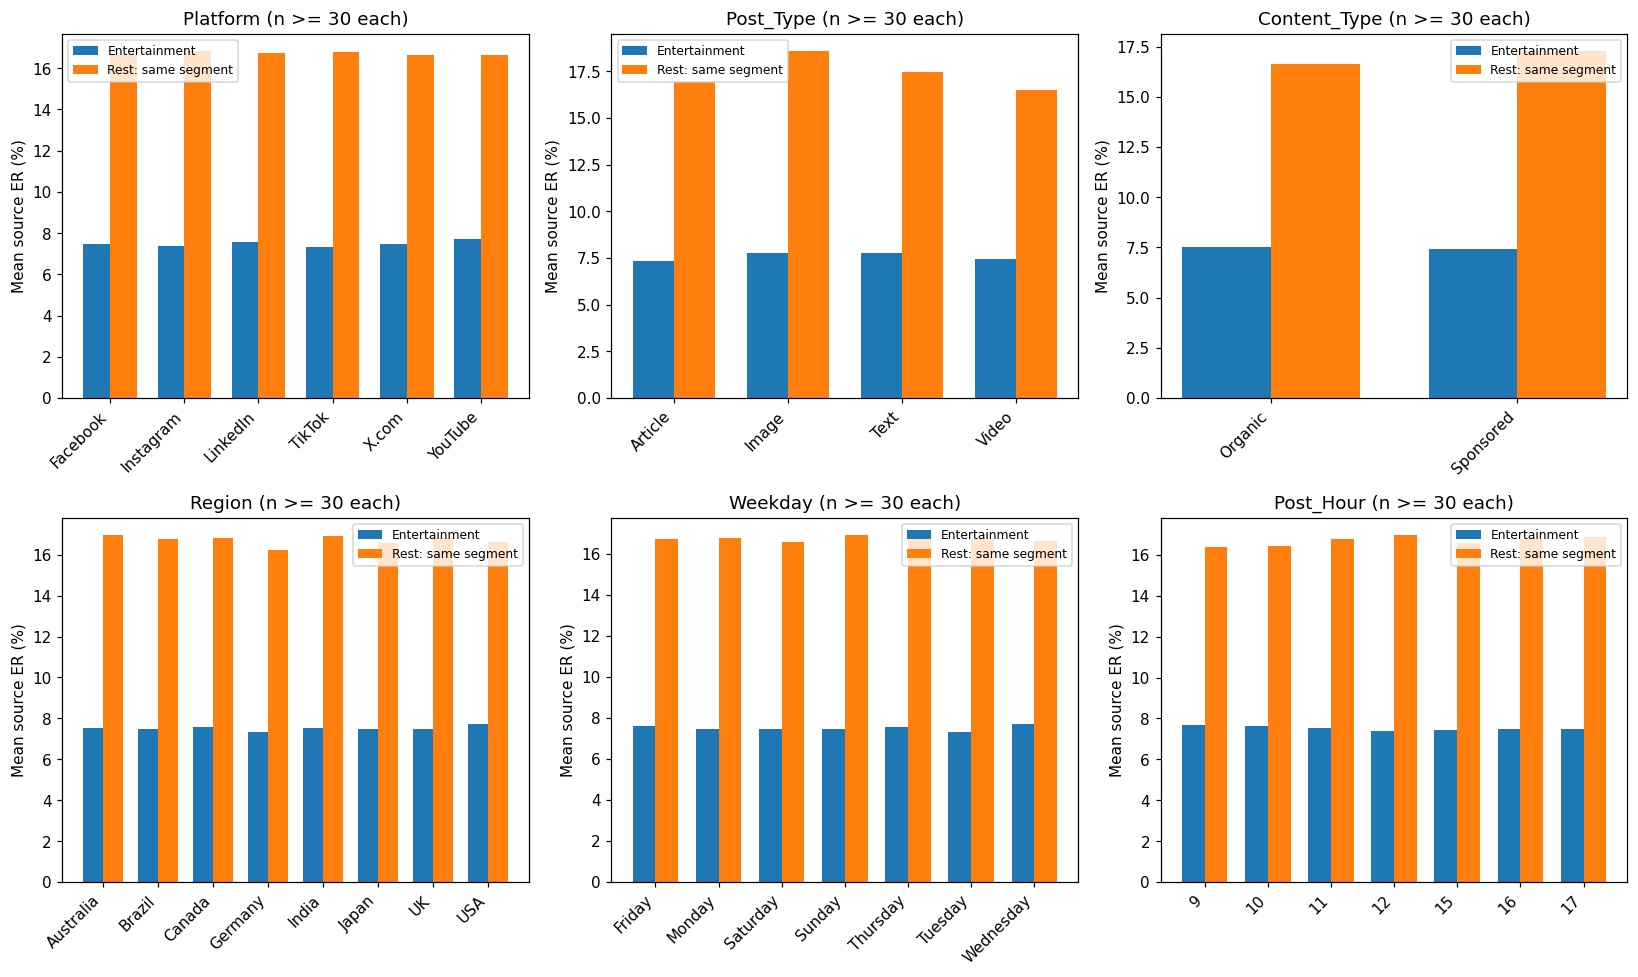

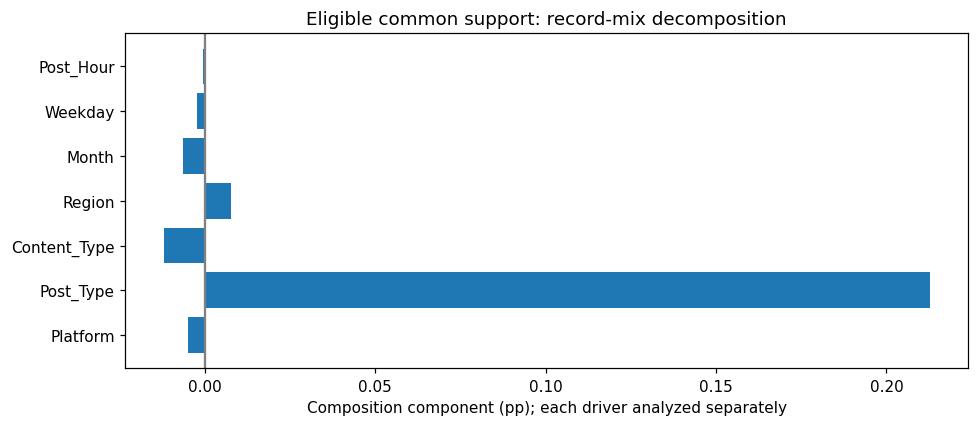

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, ["Platform", "Post_Type", "Content_Type", "Region", "Weekday", "Post_Hour"]):
    t = drivers[col].loc[drivers[col].eligible]
    x = np.arange(len(t))
    ax.bar(x-.18, t.mean_E, width=.36, label='Entertainment')
    ax.bar(x+.18, t.mean_R, width=.36, label='Rest: same segment')
    ax.set_xticks(x, t.index.astype(str), rotation=45, ha='right')
    ax.set_title(col+" (n >= 30 each)")
    ax.set_ylabel('Mean source ER (%)')
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures / 'driver_comparison.png', dpi=150, bbox_inches='tight')
fig, ax = plt.subplots(figsize=(9, 4))
t = effects.drop('Main_Hashtag')
ax.barh(t.index, t.composition_pp)
ax.axvline(0, color='gray')
ax.set_xlabel('Composition component (pp); each driver analyzed separately')
ax.set_title('Eligible common support: record-mix decomposition')
fig.tight_layout()
fig.savefig(figures / 'composition_components.png', dpi=150, bbox_inches='tight')


## Hashtag: common support và khả năng tách effect

Một tag không có comparator đủ mẫu không thể xác định effect độc lập. Tag chỉ là Main_Hashtag và gắn chặt với category. Không diễn giải ER thấp ở tag của Entertainment thành nguyên nhân từ hashtag.


In [4]:
cross = pd.crosstab(data.Main_Hashtag, data.Content_Category)
save(cross, 'hashtag_category_counts')
display(cross)
tag_purity = cross.max(axis=1)/cross.sum(axis=1)
print('Hashtags appearing in only one category:', int(cross.gt(0).sum(axis=1).eq(1).sum()), '/', len(cross))
print('Entertainment coverage in eligible hashtag comparisons:', effects.loc['Main_Hashtag', 'coverage_E_pct'])


Content_Category,Customer Story,Educational,Entertainment,Event / Webinar,Product Promotion
Main_Hashtag,,,,,
#BehindTheScenes,0,0,0,4,0
#CaseStudy2025,0,1,0,0,0
#CustomerStory,246,756,0,0,2
#CustomerSuccess,59,32,0,0,0
#DidYouKnow,0,78,46,0,0
#EventRecap,0,0,0,365,0
#EventSummary,0,0,0,38,0
#FeatureHighlight,0,0,0,0,353
#FunContent,0,0,298,0,0


Hashtags appearing in only one category: 12 / 18
Entertainment coverage in eligible hashtag comparisons: 5.251141552511415
